# 13. Tutorial 13

**Course:** High Switching Frequency Power Converters

## 13.1 Spectra of the switch node and the input current

Buck $48~\mathrm{V} \to 12~\mathrm{V}$, $100~\mathrm{W}$, $f_\mathrm{sw} = 1~\mathrm{MHz}$, $D = 0.25$, $L = 2.2~\mu\mathrm{H}$, edges $t_\mathrm{r} = t_\mathrm{f} = 2~\mathrm{ns}$.

13.1.1 Import necessary modules (numpy as np, matplotlib.pyplot as plt) and create a function `harmonics(x)` that returns the harmonic amplitudes of one sampled period with `np.fft.rfft`. Build one period of the trapezoidal switch-node voltage ($10^5$ samples), plot the amplitudes in $\mathrm{dB\mu V}$ up to $1~\mathrm{GHz}$ together with the envelope and print $c_1$ to $c_6$.

13.1.2 Build one period of the input current including the inductor ripple and print its first five harmonics next to the rectangular estimate $(2I_\mathrm{o}/(n\pi))\,|\sin(n\pi D)|$.


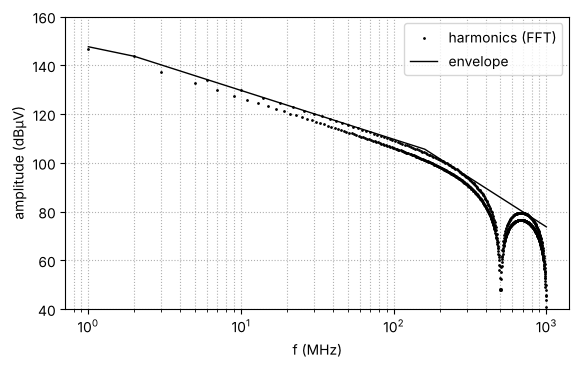

corners 1.27 MHz and 159 MHz, flat level 147.6 dBuV
c1 =  21.61 V:  146.7 dBuV amplitude,  143.7 dBuV rms
c2 =  15.28 V:  143.7 dBuV amplitude,  140.7 dBuV rms
c3 =   7.20 V:  137.1 dBuV amplitude,  134.1 dBuV rms
c4 =   0.00 V:  -60.0 dBuV amplitude,  -60.0 dBuV rms
c5 =   4.32 V:  132.7 dBuV amplitude,  129.7 dBuV rms
c6 =   5.09 V:  134.1 dBuV amplitude,  131.1 dBuV rms


In [1]:
# Subtask 13.1.1 Import necessary modules and compute the switch-node spectrum
import numpy as np
import matplotlib.pyplot as plt

A, D, fsw, tr = 48.0, 0.25, 1e6, 2e-9
Ts = 1 / fsw
N = 100000                                   # samples per period, 10 ps resolution
t = np.arange(N) * Ts / N
t0 = 100e-9                                  # centre of the rising edge


def harmonics(x):
    """Amplitudes of the harmonics 1, 2, 3, ... of one sampled period."""
    X = np.fft.rfft(x) / len(x)
    return 2 * np.abs(X[1:])


def trapezoid(t, A, D, tr):
    """Pulse of width D*Ts between the 50 % points, linear edges of duration tr."""
    rise = np.clip((t - t0) / tr + 0.5, 0, 1)
    fall = np.clip((t0 + D * Ts - t) / tr + 0.5, 0, 1)
    return A * np.minimum(rise, fall)


def dbuv(x):
    return 20 * np.log10(np.maximum(x, 1e-9) / 1e-6)


v = trapezoid(t, A, D, tr)
c = harmonics(v)
fh_all = np.arange(1, len(c) + 1) * fsw
env = 2 * A * D * np.minimum(1, 1 / (np.pi * D * Ts * fh_all)) * np.minimum(1, 1 / (np.pi * tr * fh_all))
k = fh_all <= 1e9
plt.figure(figsize=(6.5, 3.8))
plt.semilogx(fh_all[k] / 1e6, dbuv(c[k]), 'k.', ms=2, label='harmonics (FFT)')
plt.semilogx(fh_all[k] / 1e6, dbuv(env[k]), 'k-', lw=1, label='envelope')
plt.xlabel('f (MHz)'); plt.ylabel('amplitude (dBµV)'); plt.ylim(40, 160)
plt.grid(True, which='both', ls=':'); plt.legend(); plt.show()
print(f"corners {1/(np.pi*D*Ts)/1e6:.2f} MHz and {1/(np.pi*tr)/1e6:.0f} MHz, flat level {dbuv(2*A*D):.1f} dBuV")
for i in range(6):
    print(f"c{i+1} = {c[i]:6.2f} V: {dbuv(c[i]):6.1f} dBuV amplitude, {dbuv(c[i]/np.sqrt(2)):6.1f} dBuV rms")


In [2]:
# Subtask 13.1.2 Input current with inductor ripple
Vin, Vo, P, L = 48.0, 12.0, 100.0, 2.2e-6
Io = P / Vo
dI = (Vin - Vo) * D * Ts / L
on = (t >= t0) & (t < t0 + D * Ts)
i_in = np.where(on, Io - dI / 2 + dI * (t - t0) / (D * Ts), 0.0)
ci = harmonics(i_in)
print(f"Io = {Io:.2f} A, ripple {dI:.2f} A peak to peak, average input current {i_in.mean():.3f} A")
for m in range(1, 6):
    rect = 2 * Io / (m * np.pi) * abs(np.sin(m * np.pi * D))
    print(f"n = {m}: {ci[m-1]:.3f} A with ripple, {rect:.3f} A rectangular")


Io = 8.33 A, ripple 4.09 A peak to peak, average input current 2.083 A
n = 1: 3.760 A with ripple, 3.751 A rectangular
n = 2: 2.685 A with ripple, 2.653 A rectangular
n = 3: 1.325 A with ripple, 1.250 A rectangular
n = 4: 0.326 A with ripple, 0.000 A rectangular
n = 5: 0.763 A with ripple, 0.750 A rectangular


### 13.1 Solution

The FFT reproduces the envelope: flat at $147.6~\mathrm{dB\mu V}$ up to $1.27~\mathrm{MHz}$, $-20~\mathrm{dB}$ per decade up to $159~\mathrm{MHz}$, $-40~\mathrm{dB}$ per decade above; every fourth harmonic is missing ($D = 0.25$). $c_1 = 21.6~\mathrm{V}$, i.e. $143.7~\mathrm{dB\mu V}$ rms. The ripple changes the first harmonic of the input current by only $0.2~\%$ ($3.76$ instead of $3.75~\mathrm{A}$), but fills in the fourth harmonic ($0.33~\mathrm{A}$).


## 13.2 LISN readings with and without filter

13.2.1 Create a function `class_b_avg(f)` for the average limit (56 to $46~\mathrm{dB\mu V}$ falling linearly with $\log f$ from 0.15 to $0.5~\mathrm{MHz}$, $46~\mathrm{dB\mu V}$ to $5~\mathrm{MHz}$, $50~\mathrm{dB\mu V}$ to $30~\mathrm{MHz}$). Compute the common-mode reading (rms per line) of the harmonics from 1 to $30~\mathrm{MHz}$ for $C_\mathrm{p} = 20~\mathrm{pF}$ without filter, with $L_\mathrm{CM} = 1.3~\mathrm{mH}$ ($10~\mathrm{pF}$ winding capacitance) and $C_\mathrm{Y} = 9.4~\mathrm{nF}$ ($1~\mathrm{nH}$, both capacitors in parallel), and with a shield ($C_\mathrm{p} = 2~\mathrm{pF}$, $L_\mathrm{CM} = 0.13~\mathrm{mH}$, $3~\mathrm{pF}$). Plot the readings against the limit and print the smallest margin.

13.2.2 The same for the differential-mode reading with $C_\mathrm{in}$ ($4.7~\mu\mathrm{F}$, $5~\mathrm{m\Omega}$, $0.5~\mathrm{nH}$): without filter, and with $L_\mathrm{f} = 4.7~\mu\mathrm{H}$ ($10~\mathrm{m\Omega}$, $20~\mathrm{pF}$), $C_\mathrm{f} = 2.2~\mu\mathrm{F}$ ($5~\mathrm{m\Omega}$, $1~\mathrm{nH}$) and the damper $R_\mathrm{d} = 0.56~\Omega$, $C_\mathrm{b} = 22~\mu\mathrm{F}$.


CM, 20 pF, no filter: smallest margin -50.6 dB at 2 MHz
CM, 20 pF, 1.3 mH, 9.4 nF: smallest margin 12.3 dB at 1 MHz
CM, 2 pF (shield), 0.13 mH, 9.4 nF: smallest margin 6.0 dB at 1 MHz


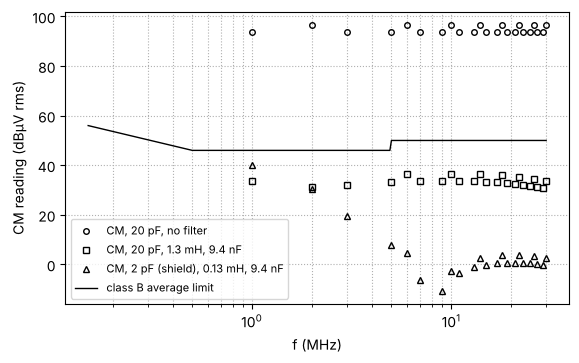

SRF of the 1.3 mH choke: 1.40 MHz


In [3]:
# Subtask 13.2.1 Average limit and common-mode reading
def class_b_avg(f):
    f = np.asarray(f, dtype=float)
    lim = np.where(f < 0.5e6, 56 - 10 * np.log10(f / 0.15e6) / np.log10(0.5 / 0.15), 46.0)
    return np.where(f >= 5e6, 50.0, lim)


nh = np.arange(1, 31)
fh = nh * fsw
s = 2j * np.pi * fh
vh = c[:30]                                   # switch-node harmonics (amplitudes)
ff = np.logspace(np.log10(0.15e6), np.log10(30e6), 300)


def cm_reading(Cp, LCM=None, CLCM=10e-12, CY=9.4e-9, LY=1e-9):
    ZCp = 1 / (s * Cp)
    if LCM is None:
        i_lisn = vh / (ZCp + 25)
    else:
        ZY = 1 / (s * CY) + s * LY
        ZL = 1 / (1 / (s * LCM) + s * CLCM)
        Zsh = 1 / (1 / ZY + 1 / (ZL + 25))
        i_lisn = vh / (ZCp + Zsh) * ZY / (ZY + ZL + 25)
    return dbuv(np.abs(i_lisn) * 25 / np.sqrt(2))   # each line: 50 Ohm times half the CM current, rms


def plot_readings(cases, ylabel):
    plt.figure(figsize=(6.5, 3.8))
    for (name, r), mk in zip(cases, ('ko', 'ks', 'k^')):
        k = r > -50                           # every fourth switch-node harmonic is zero for D = 0.25
        plt.semilogx(fh[k] / 1e6, r[k], mk, ms=4, mfc='none', label=name)
        m = class_b_avg(fh[k]) - r[k]
        print(f"{name}: smallest margin {m.min():.1f} dB at {fh[k][np.argmin(m)]/1e6:.0f} MHz")
    plt.semilogx(ff / 1e6, class_b_avg(ff), 'k-', lw=1, label='class B average limit')
    plt.xlabel('f (MHz)'); plt.ylabel(ylabel); plt.grid(True, which='both', ls=':')
    plt.legend(fontsize=8); plt.show()


cm_cases = [("CM, 20 pF, no filter", cm_reading(20e-12)),
            ("CM, 20 pF, 1.3 mH, 9.4 nF", cm_reading(20e-12, 1.3e-3)),
            ("CM, 2 pF (shield), 0.13 mH, 9.4 nF", cm_reading(2e-12, 0.13e-3, CLCM=3e-12))]
plot_readings(cm_cases, 'CM reading (dBµV rms)')
print(f"SRF of the 1.3 mH choke: {1/(2*np.pi*np.sqrt(1.3e-3*10e-12))/1e6:.2f} MHz")


DM, no filter: smallest margin -46.3 dB at 1 MHz
DM, 4.7 µH, 2.2 µF, damper: smallest margin 6.7 dB at 1 MHz


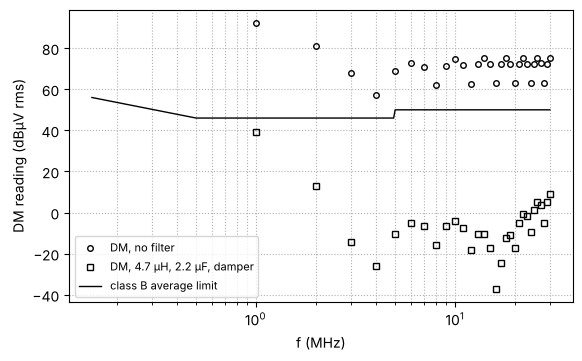

SRF of Cf: 3.39 MHz, SRF of Lf: 16.42 MHz


In [4]:
# Subtask 13.2.2 Differential-mode reading
ih = ci[:30]                                  # input-current harmonics with ripple
Cin, ESR, ESL = 4.7e-6, 5e-3, 0.5e-9
Lf, DCR, EPC = 4.7e-6, 10e-3, 20e-12
Cf, ESRf, ESLf = 2.2e-6, 5e-3, 1e-9
Cb, Rd = 22e-6, 0.56


def dm_reading(filt=True):
    Zcin = ESR + s * ESL + 1 / (s * Cin)
    if not filt:
        v_line = ih * np.abs(1 / (1 / Zcin + 1 / 100)) / 2
    else:
        Zcf = ESRf + s * ESLf + 1 / (s * Cf)
        Zp = 1 / (1 / Zcf + 1 / 100)
        ZL = 1 / (1 / (DCR + s * Lf) + s * EPC)
        Zd = Rd + 1 / (s * Cb)
        Zsh = 1 / (1 / Zcin + 1 / Zd + 1 / (ZL + Zp))
        v_line = ih * np.abs(Zsh * Zp / (ZL + Zp)) / 2
    return dbuv(v_line / np.sqrt(2))


dm_cases = [("DM, no filter", dm_reading(False)), ("DM, 4.7 µH, 2.2 µF, damper", dm_reading(True))]
plot_readings(dm_cases, 'DM reading (dBµV rms)')
print(f"SRF of Cf: {1/(2*np.pi*np.sqrt(Cf*ESLf))/1e6:.2f} MHz, SRF of Lf: {1/(2*np.pi*np.sqrt(Lf*EPC))/1e6:.2f} MHz")


### 13.2 Solution

Common mode without filter: $93.6~\mathrm{dB\mu V}$ for odd $n$ and $96.6~\mathrm{dB\mu V}$ for $n = 2, 6, 10, \ldots$, flat up to $30~\mathrm{MHz}$; worst margin $-50.6~\mathrm{dB}$ at $2~\mathrm{MHz}$. With $1.3~\mathrm{mH}$ and $9.4~\mathrm{nF}$ the smallest margin is $12.3~\mathrm{dB}$ at $1~\mathrm{MHz}$: the winding capacitance resonates with the choke at $1.40~\mathrm{MHz}$ and raises its impedance at $1~\mathrm{MHz}$. Above the resonance the $10~\mathrm{pF}$, not the inductance, set the attenuation, which is still sufficient because the Y capacitors have a low impedance. With the shield, $0.13~\mathrm{mH}$ give $6.0~\mathrm{dB}$ margin. Differential mode: $-46.3~\mathrm{dB}$ without filter, $+6.7~\mathrm{dB}$ with filter and damper, both at $1~\mathrm{MHz}$. Above the self-resonances ($3.4$ and $16.4~\mathrm{MHz}$) the attenuation stops growing, but the readings stay far below the limit.


## 13.3 Output impedance of the filter and damping

13.3.1 Compute $|Z_\mathrm{out}(f)|$ seen by the converter for a stiff source: undamped, with $C_\mathrm{b} = 22~\mu\mathrm{F}$ and $R_\mathrm{d}$ from the formula of Erickson and Maksimović, and with $R_\mathrm{d} = 1~\Omega$. Find the $R_\mathrm{d}$ that minimises the peak numerically and compare with $|R_\mathrm{in}| = V^2/P$.

13.3.2 Replace the stiff source by the LISN (per line $50~\Omega$ behind $0.1~\mu\mathrm{F}$, in parallel with $50~\mu\mathrm{H}$ to a stiff supply) together with $C_\mathrm{f}$. Which resonance appears, and does the damper handle it as well?


Rin = -23.0 Ohm, f0 = 33.9 kHz, R0 = 1.00 Ohm
n = 4.68: Rd = 0.56 Ohm, predicted peak 0.78 Ohm


numerical optimum: Rd = 0.55 Ohm, peak 0.76 Ohm
undamped: peak 66.66 Ohm at 33.9 kHz
Rd = 0.56 Ohm: peak 0.76 Ohm at 18.7 kHz
Rd = 1 Ohm: peak 1.04 Ohm at 29.5 kHz


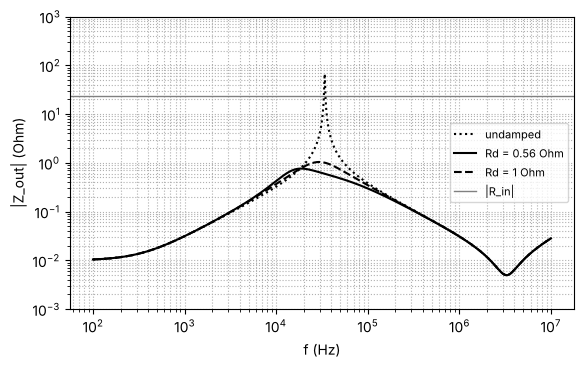

In [5]:
# Subtask 13.3.1 Output impedance of the filter with a stiff source
Rin = Vin**2 / P
f = np.logspace(2, 7, 20001)
s3 = 2j * np.pi * f


def zout(Rd=None, Cb=22e-6, source='stiff'):
    Zcin = ESR + s3 * ESL + 1 / (s3 * Cin)
    ZL = 1 / (1 / (DCR + s3 * Lf) + s3 * EPC)
    if source == 'stiff':
        Zs = 0
    else:   # LISN: per line 50 Ohm behind 0.1 uF, in parallel with 50 uH to a stiff supply; Cf across
        Zline = 1 / (1 / (50 + 1 / (s3 * 0.1e-6)) + 1 / (s3 * 50e-6))
        Zcf = ESRf + s3 * ESLf + 1 / (s3 * Cf)
        Zs = 1 / (1 / Zcf + 1 / (2 * Zline))
    Y = 1 / Zcin + 1 / (ZL + Zs)
    if Rd is not None:
        Y = Y + 1 / (Rd + 1 / (s3 * Cb))
    return np.abs(1 / Y)


R0 = np.sqrt(Lf / Cin)
n = 22e-6 / Cin
Rd_opt = R0 * np.sqrt((2 + n) * (4 + 3 * n) / (2 * n**2 * (4 + n)))
print(f"Rin = -{Rin:.1f} Ohm, f0 = {1/(2*np.pi*np.sqrt(Lf*Cin))/1e3:.1f} kHz, R0 = {R0:.2f} Ohm")
print(f"n = {n:.2f}: Rd = {Rd_opt:.2f} Ohm, predicted peak {R0*np.sqrt(2*(2+n))/n:.2f} Ohm")
Rd_grid = np.linspace(0.1, 3, 291)
peaks = [zout(r).max() for r in Rd_grid]
print(f"numerical optimum: Rd = {Rd_grid[np.argmin(peaks)]:.2f} Ohm, peak {min(peaks):.2f} Ohm")
plt.figure(figsize=(6.5, 3.8))
for lab, z, st in (("undamped", zout(), 'k:'), (f"Rd = {Rd_opt:.2f} Ohm", zout(Rd_opt), 'k-'), ("Rd = 1 Ohm", zout(1.0), 'k--')):
    plt.loglog(f, z, st, label=lab)
    print(f"{lab}: peak {z.max():.2f} Ohm at {f[np.argmax(z)]/1e3:.1f} kHz")
plt.axhline(Rin, color='gray', lw=1, label='|R_in|')
plt.xlabel('f (Hz)'); plt.ylabel('|Z_out| (Ohm)'); plt.ylim(1e-3, 1e3)
plt.grid(True, which='both', ls=':'); plt.legend(fontsize=8); plt.show()


undamped: peak 1220.6 Ohm at 6.0 kHz
Rd = 0.56 Ohm: peak 11.0 Ohm at 2.9 kHz
Rd = 1 Ohm: peak 6.6 Ohm at 3.0 kHz


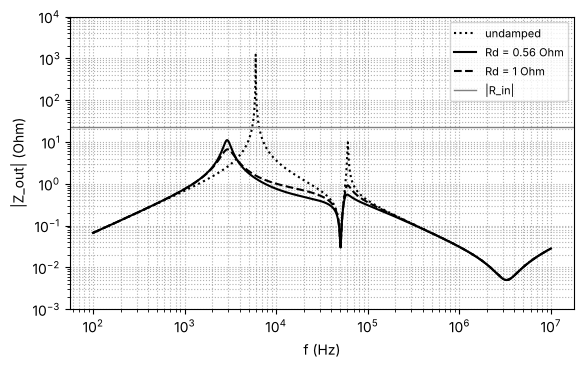

LISN inductance 2 x 50 uH with Cin + Cf = 6.9 uF: 6.1 kHz


In [6]:
# Subtask 13.3.2 Output impedance with the LISN as source
plt.figure(figsize=(6.5, 3.8))
for lab, r, st in (("undamped", None, 'k:'), (f"Rd = {Rd_opt:.2f} Ohm", Rd_opt, 'k-'), ("Rd = 1 Ohm", 1.0, 'k--')):
    z = zout(r, source='lisn')
    plt.loglog(f, z, st, label=lab)
    kk = np.argmax(z)
    print(f"{lab}: peak {z[kk]:.1f} Ohm at {f[kk]/1e3:.1f} kHz")
plt.axhline(Rin, color='gray', lw=1, label='|R_in|')
plt.xlabel('f (Hz)'); plt.ylabel('|Z_out| (Ohm)'); plt.ylim(1e-3, 1e4)
plt.grid(True, which='both', ls=':'); plt.legend(fontsize=8); plt.show()
Ctot = Cin + Cf
print(f"LISN inductance 2 x 50 uH with Cin + Cf = {Ctot*1e6:.1f} uF: {1/(2*np.pi*np.sqrt(100e-6*Ctot))/1e3:.1f} kHz")


### 13.3 Solution

$R_\mathrm{in} = -23~\Omega$. Stiff source: the undamped filter peaks at $66.7~\Omega$ ($33.9~\mathrm{kHz}$), almost three times $|R_\mathrm{in}|$. The optimum $R_\mathrm{d} = 0.56~\Omega$ gives $0.76~\Omega$ ($0.78~\Omega$ predicted; the numerical optimum, $0.55~\Omega$, agrees); $R_\mathrm{d} = 1~\Omega$ gives $1.04~\Omega$. With the LISN (model: stiff supply behind the $50~\mu\mathrm{H}$) the LISN inductors resonate with $C_\mathrm{in} + C_\mathrm{f}$ at $6~\mathrm{kHz}$, $1.2~\mathrm{k\Omega}$ undamped: a converter that is stable on the bench can oscillate in the EMI test. The damper on $C_\mathrm{in}$ also damps this resonance: $11.0~\Omega$ with $0.56~\Omega$, $6.6~\Omega$ with $1~\Omega$. $R_\mathrm{d} = 1~\Omega$ is the better compromise for both sources.


## 13.4 Thermal network

13.4.1 Solve the network of Task 3 in steady state with electro-thermal feedback by fixed-point iteration ($P_\mathrm{T} = 1.2~\mathrm{W} + 0.4~\mathrm{W}\,[1 + 0.008\,(T_\mathrm{j} - 25)]$). Print $T_\mathrm{j}$ for 16 vias, 32 vias and 16 copper-filled vias.

13.4.2 Model the path as a Cauer ladder with heat capacities $4~\mathrm{mJ/K}$ (die), $20~\mathrm{mJ/K}$ (package and pad), $1~\mathrm{J/K}$ (board under the transistor) and $45~\mathrm{J/K}$ (heat sink). Simulate the start-up from $50~^\circ\mathrm{C}$, then an overload of $20~\mathrm{ms}$ with twice the current (conduction loss times four) from steady state, and plot $T_\mathrm{j}$.


In [7]:
# Subtask 13.4.1 Steady state with electro-thermal feedback
Ta, Rsa, Prest = 50.0, 4.0, 3.4
Rjc, Rsp = 0.8, 1.5
Rtim = 1e-3 / (3.0 * 1e-4)                       # 1 mm gap pad, 3 W/(m K), 10 mm x 10 mm
k_cu, l_via, d, tp = 390.0, 1.6e-3, 0.3e-3, 25e-6
R_via = l_via / (k_cu * np.pi * (d - tp) * tp)   # plated barrel
R_filled = l_via / (k_cu * np.pi * d**2 / 4)     # copper-filled via
Psw, Pc25, alpha = 1.2, 0.4, 0.008


def p_t(Tj, k=1.0):
    return Psw + k**2 * Pc25 * (1 + alpha * (Tj - 25))


def tj_steady(Rvias, feedback=True):
    Rpath = Rjc + Rsp + Rvias + Rtim
    Tj = Ta
    for _ in range(200):
        P = p_t(Tj) if feedback else Psw + Pc25
        Tj = Ta + Rsa * (Prest + P) + Rpath * P
    return Tj, P, Rpath


print(f"R_via = {R_via:.0f} K/W, copper-filled {R_filled:.0f} K/W, R_TIM = {Rtim:.2f} K/W")
for name, Rv in (("16 vias", R_via / 16), ("32 vias", R_via / 32), ("16 filled vias", R_filled / 16)):
    Tc, _, Rp = tj_steady(Rv, False)
    Tf, Pf, _ = tj_steady(Rv, True)
    print(f"{name}: path {Rp:.1f} K/W, Tj = {Tc:.1f} C at constant loss, {Tf:.1f} C with feedback (P = {Pf:.2f} W)")


R_via = 190 K/W, copper-filled 58 K/W, R_TIM = 3.33 K/W
16 vias: path 17.5 K/W, Tj = 98.0 C at constant loss, 103.4 C with feedback (P = 1.85 W)
32 vias: path 11.6 K/W, Tj = 88.5 C at constant loss, 91.8 C with feedback (P = 1.81 W)
16 filled vias: path 9.3 K/W, Tj = 84.8 C at constant loss, 87.5 C with feedback (P = 1.80 W)


start-up: Tj = 103.4 C after 1500 s, 63 % of the rise after 28 s


overload: P_T rises from 1.85 W to 3.80 W, Tj peaks at 106.1 C (+2.7 K)


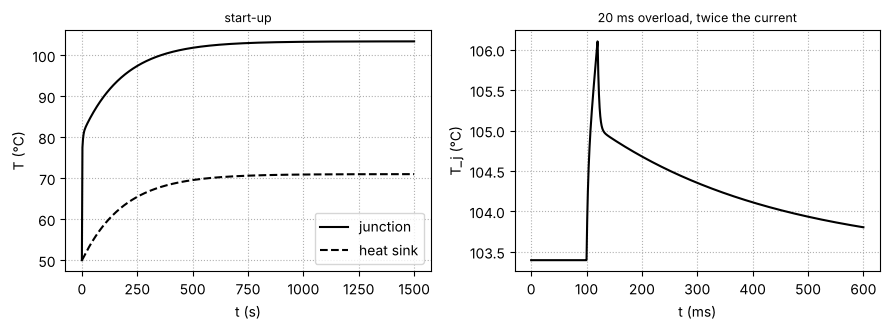

In [8]:
# Subtask 13.4.2 Cauer ladder: start-up and a 20 ms overload
from scipy.integrate import solve_ivp

Cth = np.array([4e-3, 20e-3, 1.0, 45.0])          # J/K: die, package and pad, board, heat sink
R12, R23, R34 = Rjc, Rsp + R_via / 16, Rtim


def rhs(t, T, kfun):
    Tj, Tp, Tb, Th = T
    q12, q23, q34, q4a = (Tj - Tp) / R12, (Tp - Tb) / R23, (Tb - Th) / R34, (Th - Ta) / Rsa
    return [(p_t(Tj, kfun(t)) - q12) / Cth[0], (q12 - q23) / Cth[1],
            (q23 - q34) / Cth[2], (q34 + Prest - q4a) / Cth[3]]


start = solve_ivp(rhs, (0, 1500), [Ta] * 4, args=(lambda t: 1.0,), method='Radau', rtol=1e-8, atol=1e-8, dense_output=True)
ts = np.linspace(0, 1500, 600)
Ts_ = start.sol(ts)
Tss = start.y[:, -1]
t63 = ts[np.argmax(Ts_[0] >= Ta + 0.63 * (Tss[0] - Ta))]
print(f"start-up: Tj = {Tss[0]:.1f} C after 1500 s, 63 % of the rise after {t63:.0f} s")

over = lambda t: 2.0 if 0.1 <= t < 0.12 else 1.0
ov = solve_ivp(rhs, (0, 0.6), Tss, args=(over,), method='Radau', rtol=1e-9, atol=1e-9, max_step=1e-4, dense_output=True)
to = np.linspace(0, 0.6, 3000)
To = ov.sol(to)
print(f"overload: P_T rises from {p_t(Tss[0]):.2f} W to {p_t(Tss[0], 2.0):.2f} W, Tj peaks at {To[0].max():.1f} C (+{To[0].max()-Tss[0]:.1f} K)")
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
ax[0].plot(ts, Ts_[0], 'k', label='junction'); ax[0].plot(ts, Ts_[3], 'k--', label='heat sink')
ax[0].set_xlabel('t (s)'); ax[0].set_ylabel('T (°C)'); ax[0].grid(True, ls=':'); ax[0].legend(); ax[0].set_title('start-up', fontsize=9)
ax[1].plot(to * 1e3, To[0], 'k'); ax[1].set_xlabel('t (ms)'); ax[1].set_ylabel('T_j (°C)')
ax[1].grid(True, ls=':'); ax[1].set_title('20 ms overload, twice the current', fontsize=9)
plt.tight_layout(); plt.show()


### 13.4 Solution

$R_\mathrm{via} = 190~\mathrm{K/W}$, copper-filled $58~\mathrm{K/W}$. $T_\mathrm{j} = 98.0$, $88.5$ and $84.8~^\circ\mathrm{C}$ at constant loss; with feedback $103.4$, $91.8$ and $87.5~^\circ\mathrm{C}$. Start-up: the junction follows the board within seconds, the heat sink needs minutes ($R_\mathrm{sa}C_\mathrm{hs} = 180~\mathrm{s}$), so a thermal measurement needs about $15~\mathrm{min}$ (five time constants) at constant load. A $20~\mathrm{ms}$ overload with twice the current doubles $P_\mathrm{T}$ to $3.8~\mathrm{W}$ but raises $T_\mathrm{j}$ by only $2.7~\mathrm{K}$: short events are carried by the heat capacity of die and package, the steady state decides.
